# 012. 권역별 비교

운정중앙·대곡·킨텍스의 접근·환승 여건과 광역버스 변화, GTX역행 마을·시내버스 이용을 비교한다. 핵심은 운정중앙과 대곡의 대비이며 킨텍스도 동일한 기준으로 제시한다.

- 2024-10-17 / 2025-11-06, 공급구조 유지 250m 격자 **126개 전체**.
- 광역버스는 **승차건수(교통카드 행 수)**, 연계버스는 **2025년 GTX역행 마을·시내버스 이용건수**.
- 기존 CSV를 읽어 비교하며 모델을 재학습하지 않는다. CSV·PNG를 별도 저장하지 않고 노트북에만 표시한다.
- 권역은 승차 격자의 소속 권역이다. 역명 정류장 하차는 실제 GTX 환승 여부의 대리지표다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display

ROOT_012 = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'config.py').is_file() and (p / 'code').is_dir())
TAB_012 = ROOT_012 / 'results/analysis/feeder_bus/tables'
ORDER_012 = ['운정중앙', '대곡', '킨텍스']
COLORS_012 = {'운정중앙': '#3264A8', '대곡': '#359475', '킨텍스': '#D18C32'}
for font in [Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
             Path(r'C:\Windows\Fonts\malgun.ttf'), Path('/Library/Fonts/NanumGothic.ttf')]:
    if font.is_file():
        fm.fontManager.addfont(str(font))
        plt.rcParams['font.family'] = fm.FontProperties(fname=str(font)).get_name()
        break
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 12,
                     'axes.titlesize': 15, 'axes.labelsize': 12,
                     'xtick.labelsize': 12, 'ytick.labelsize': 11, 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)

base_012 = pd.read_csv(ROOT_012 / 'data/final/gtx_a/S1_126격자_건수기준_기초표.csv')
feeder_012 = pd.read_csv(next(TAB_012.glob('H11a_*.csv')))
routes_012 = pd.read_csv(next(TAB_012.glob('H13f_*.csv')), dtype={'rte_id': str, '노선번호': str})
coef_012 = pd.read_csv(next(TAB_012.glob('H12a_*.csv')))
fit_012 = pd.read_csv(next(TAB_012.glob('H12b_*.csv')))
for frame in [base_012, feeder_012]:
    assert len(frame) == 126 and frame['셀 ID'].is_unique
assert set(base_012['셀 ID']) == set(feeder_012['셀 ID'])
df_012 = base_012.merge(feeder_012[['셀 ID','권역','광역 2024','광역 2025','Δ광역','GTX역행 2025']],
                       on='셀 ID', validate='one_to_one')
assert df_012['nearest_station'].eq(df_012['권역']).all()
for a,b in [('board_2024','광역 2024'),('board_2025','광역 2025'),('change','Δ광역')]:
    np.testing.assert_allclose(df_012[a],df_012[b])
assert np.isfinite(df_012[['board_2024','board_2025','change','walk_min','GTX역행 2025']].to_numpy()).all()
BANDS_012 = ['20분 이하', '20분 초과~50분 이하', '50분 초과']
df_012['보행시간 구간'] = pd.cut(df_012['walk_min'], [-np.inf,20,50,np.inf], labels=BANDS_012)
assert df_012.groupby('권역').size().reindex(ORDER_012).tolist() == [63,37,26]
assert int(df_012['board_2024'].sum()) == 7110 and int(df_012['board_2025'].sum()) == 5517
assert int(df_012['GTX역행 2025'].sum()) == 1015

def clean_axes_012(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.18)

print('126개 격자 연결 확인 · 운정중앙 63 / 대곡 37 / 킨텍스 26')
print('광역버스: 7,110 → 5,517건 / 2025년 GTX역행: 1,015건')

126개 격자 연결 확인 · 운정중앙 63 / 대곡 37 / 킨텍스 26
광역버스: 7,110 → 5,517건 / 2025년 GTX역행: 1,015건


## 1. 환승 시설과 현장답사 비교

아래는 **사용자가 전달한 답사 관찰을 정리한 표**다. 사진·출입구·정류장 방향별 재확인이 필요한 내용을 수치나 확정 사실로 채우지 않았다. ‘짧음/길다’ 대신 실제 동선·측정값을 기록한다.

In [2]:
facility_012 = pd.DataFrame({
    '비교 항목': ['역 성격','버스 접근 공간','주차 여건','하차 정류장 → 출입구 → 개찰구','보완할 현장 기록'],
    '운정중앙': ['신설 GTX역','역 환승센터 관찰(사용자 답사)','큰 임시 주차장 관찰(사용자 답사)',
              '측정 전: 출입구·동선별 거리/시간 확인 필요','환승센터 위치, 대기·횡단·승하차 동선 사진'],
    '대곡': ['기존 철도 환승역에 GTX 추가','도로 중앙차로 정류장 이용 관찰(사용자 답사)',
           '확인 필요','측정 전: 버스 주행시간과 하차 후 이동시간 구분','도로 횡단·우회, 출입구별 접근 및 주차 여건'],
    '킨텍스': ['신설 GTX역','답사 사진·메모 확인 필요','확인 필요','측정 전: 정류장·출입구별 확인 필요',
             '연계버스 정류장 위치와 출입구 연결']
})
display(facility_012)

,비교 항목,운정중앙,대곡,킨텍스
0,역 성격,신설 GTX역,기존 철도 환승역에 GTX 추가,신설 GTX역
1,버스 접근 공간,역 환승센터 관찰(사용자 답사),도로 중앙차로 정류장 이용 관찰(사용자 답사),답사 사진·메모 확인 필요
2,주차 여건,큰 임시 주차장 관찰(사용자 답사),확인 필요,확인 필요
3,하차 정류장 → 출입구 → 개찰구,측정 전: 출입구·동선별 거리/시간 확인 필요,측정 전: 버스 주행시간과 하차 후 이동시간 구분,측정 전: 정류장·출입구별 확인 필요
4,보완할 현장 기록,"환승센터 위치, 대기·횡단·승하차 동선 사진","도로 횡단·우회, 출입구별 접근 및 주차 여건",연계버스 정류장 위치와 출입구 연결


## 2. 광역버스 승차건수 변화

권역 전체 변화율은 **합계의 변화율**이다. 격자별 변화율을 단순 평균하지 않는다. 분석격자 내부 실적이며 노선 전체 구간 실적이 아니다.

,격자수,개통전건수,개통후건수,변화량,광역변화율(%)
권역,,,,,
운정중앙,63,2568,1896,-672,-26.17
대곡,37,1050,1004,-46,-4.38
킨텍스,26,3492,2617,-875,-25.06


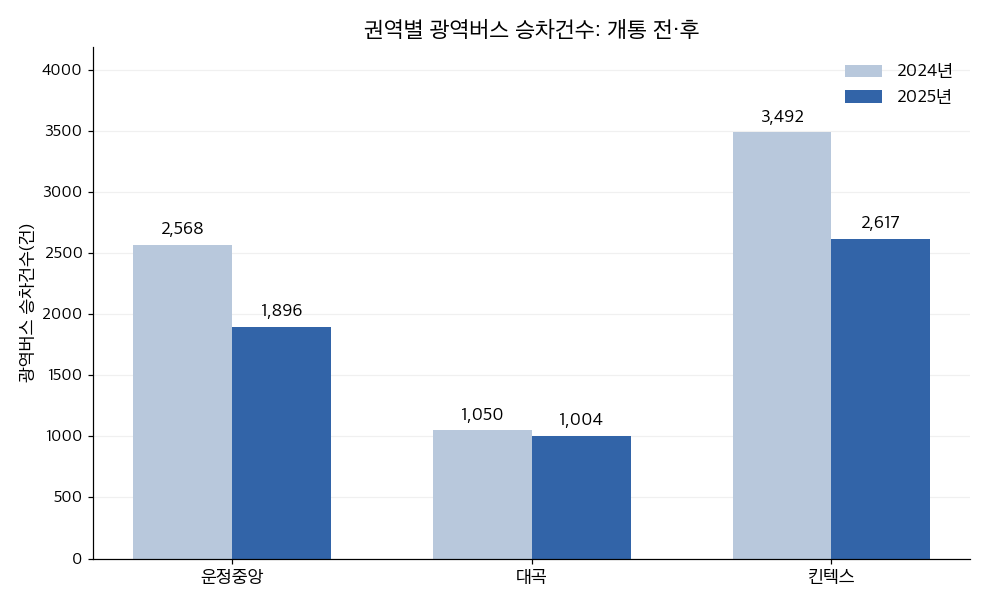

In [3]:
region_012 = df_012.groupby('권역').agg(
    격자수=('셀 ID','size'), 개통전건수=('board_2024','sum'), 개통후건수=('board_2025','sum'),
    변화량=('change','sum'), GTX역행2025=('GTX역행 2025','sum'),
    역행이용격자=('GTX역행 2025',lambda s: int(s.gt(0).sum()))).reindex(ORDER_012)
region_012['광역변화율(%)'] = 100 * region_012['변화량'] / region_012['개통전건수']
region_012['역행격자당평균(건)'] = region_012['GTX역행2025'] / region_012['격자수']
region_012['역행이용격자비율(%)'] = 100 * region_012['역행이용격자'] / region_012['격자수']
display(region_012[['격자수','개통전건수','개통후건수','변화량','광역변화율(%)']].round(2))
fig, ax = plt.subplots(figsize=(9,5.5))
x = np.arange(3); width = .33
for offset, column, label, color in [(-width/2,'개통전건수','2024년','#B8C8DC'),
                                    (width/2,'개통후건수','2025년','#3264A8')]:
    bars = ax.bar(x+offset,region_012[column],width,label=label,color=color)
    ax.bar_label(bars,labels=[f'{v:,}' for v in region_012[column]],padding=5,fontsize=12,fontweight='bold')
ax.set_xticks(x,ORDER_012);ax.set_ylim(0,region_012['개통전건수'].max()*1.2)
ax.set_ylabel('광역버스 승차건수(건)');ax.set_title('권역별 광역버스 승차건수: 개통 전·후')
ax.legend(frameon=False);clean_axes_012(ax);fig.tight_layout();plt.show()

### 같은 보행시간 구간의 광역버스 변화율

구간은 **20분 이하 / 20분 초과~50분 이하 / 50분 초과**다. 같은 구간이어도 정확한 보행시간·인구·노선 공급 등이 동일한 것은 아니다. 특히 대곡 20분 이하는 격자 1개(5→5건)다.

보행시간 구간별 격자 수
광역버스 합계 변화율(%)


권역,운정중앙,대곡,킨텍스
보행시간 구간,,,
20분 이하,6,1,4
20분 초과~50분 이하,19,23,14
50분 초과,38,13,8


권역,운정중앙,대곡,킨텍스
보행시간 구간,,,
20분 이하,-47.49,0.00,-26.42
20분 초과~50분 이하,-25.08,-3.02,-23.77
50분 초과,-6.07,-10.93,-28.65


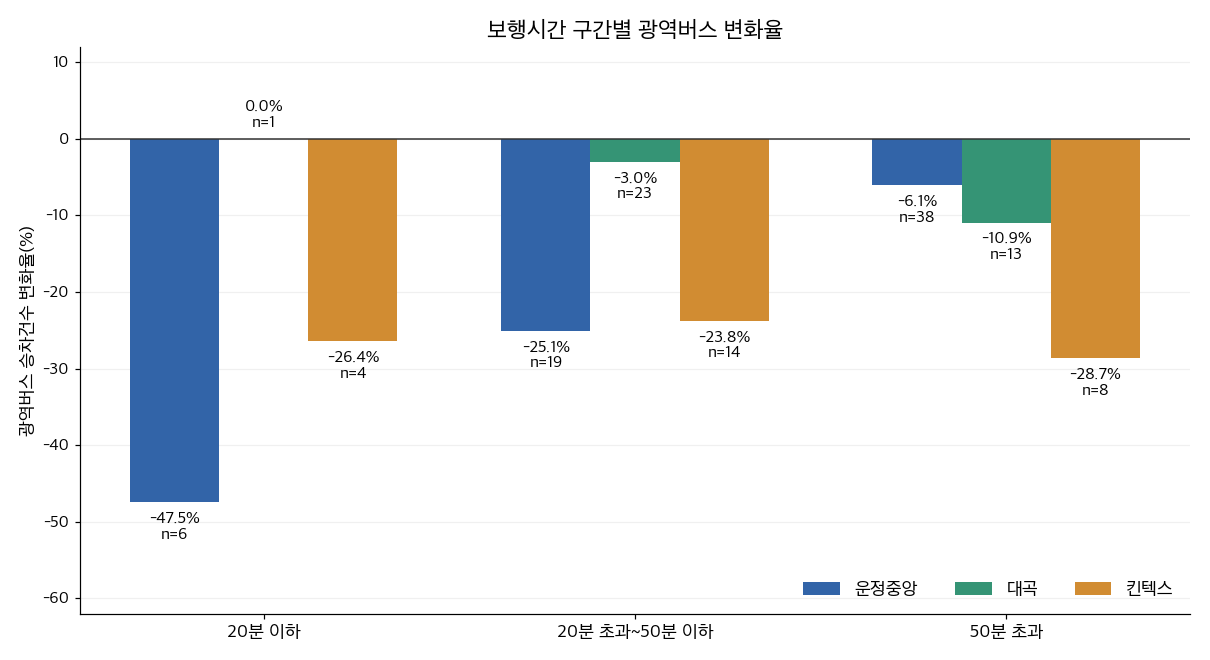

In [4]:
band_012 = df_012.groupby(['권역','보행시간 구간'],observed=True).agg(
    격자수=('셀 ID','size'), 개통전건수=('board_2024','sum'), 개통후건수=('board_2025','sum'),
    GTX역행합계=('GTX역행 2025','sum'), 역행격자당평균=('GTX역행 2025','mean'))
band_012['광역변화율(%)'] = 100 * (band_012['개통후건수'] / band_012['개통전건수'].replace(0,np.nan)-1)
band_rates_012 = band_012['광역변화율(%)'].unstack('권역').reindex(index=BANDS_012,columns=ORDER_012)
band_n_012 = band_012['격자수'].unstack('권역').reindex(index=BANDS_012,columns=ORDER_012)
print('보행시간 구간별 격자 수');display(band_n_012)
print('광역버스 합계 변화율(%)');display(band_rates_012.round(2))
fig,ax = plt.subplots(figsize=(11,6));x=np.arange(3);width=.24
for j,station in enumerate(ORDER_012):
    values=band_rates_012[station];bars=ax.bar(x+(j-1)*width,values,width,color=COLORS_012[station],label=station)
    for bar,value,n in zip(bars,values,band_n_012[station]):
        ax.annotate(f'{value:.1f}%\nn={n}',(bar.get_x()+bar.get_width()/2,value),
                    xytext=(0,-6 if value<0 else 6),textcoords='offset points',ha='center',
                    va='top' if value<0 else 'bottom',fontsize=11)
ax.axhline(0,color='#333333',lw=1);ax.set_ylim(-62,12)
ax.set_xticks(x,['20분 이하','20분 초과~50분 이하','50분 초과']);ax.set_ylabel('광역버스 승차건수 변화율(%)')
ax.set_title('보행시간 구간별 광역버스 변화율');ax.legend(frameon=False,ncol=3,loc='lower right')
clean_axes_012(ax);fig.tight_layout();plt.show()

## 3. GTX역행 마을·시내버스 이용

2025년의 **이용건수**를 비교한다. 개통 전후 증가량 또는 실제 GTX 환승건수로 해석하지 않는다. 권역마다 격자 수가 달라 합계와 격자당 평균을 함께 제시한다. 평균에는 이용건수가 0인 격자도 포함한다.

,격자수,GTX역행2025,역행이용격자,역행이용격자비율(%),역행격자당평균(건)
권역,,,,,
운정중앙,63,672.0,21,33.33,10.67
대곡,37,230.0,13,35.14,6.22
킨텍스,26,113.0,9,34.62,4.35


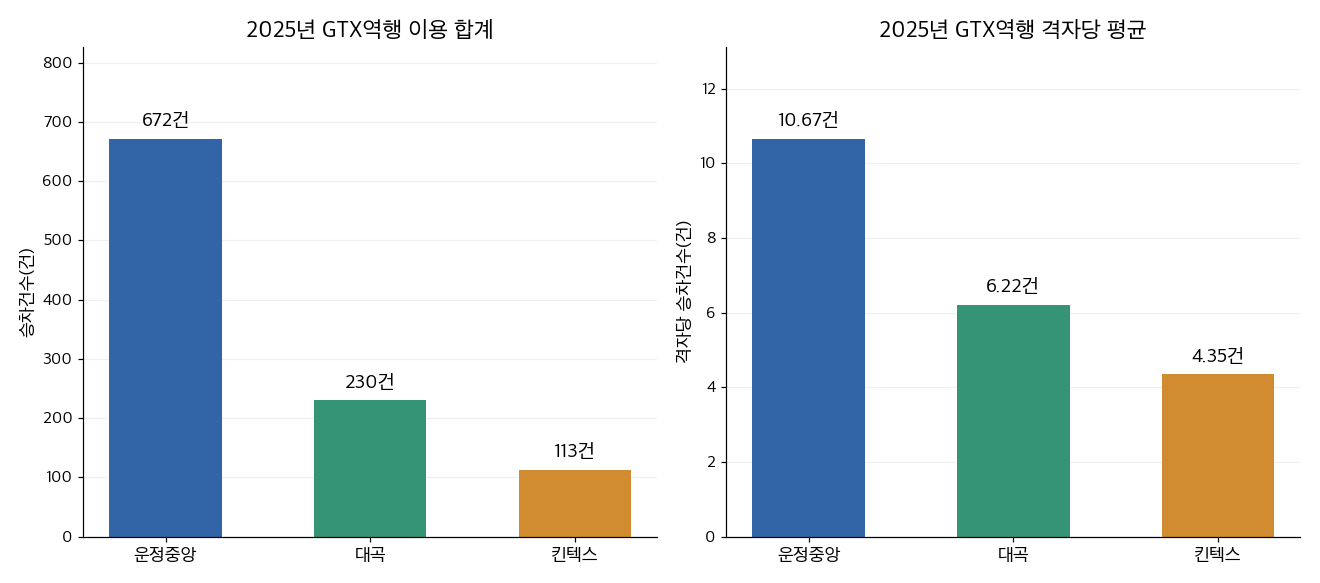

In [5]:
display(region_012[['격자수','GTX역행2025','역행이용격자','역행이용격자비율(%)','역행격자당평균(건)']].round(2))
fig,axes=plt.subplots(1,2,figsize=(12,5.3))
for ax,column,title,ylabel in [(axes[0],'GTX역행2025','2025년 GTX역행 이용 합계','승차건수(건)'),
                              (axes[1],'역행격자당평균(건)','2025년 GTX역행 격자당 평균','격자당 승차건수(건)')]:
    bars=ax.bar(ORDER_012,region_012[column],color=[COLORS_012[s] for s in ORDER_012],width=.55)
    labels=[f'{int(v):,}건' if column=='GTX역행2025' else f'{v:.2f}건' for v in region_012[column]]
    ax.bar_label(bars,labels=labels,padding=6,fontsize=13,fontweight='bold')
    ax.set_ylim(0,region_012[column].max()*1.23);ax.set_title(title);ax.set_ylabel(ylabel);clean_axes_012(ax)
fig.tight_layout();plt.show()

### 보행시간 구간별 격자당 GTX역행 이용건수

동일한 넓은 구간 안에서의 기술적 비교다. “보행시간이 완전히 같아도 2배” 또는 “환승센터 때문에 2배”로 해석하지 않는다.

격자당 GTX역행 이용건수(건, 0건 격자 포함)


권역,운정중앙,대곡,킨텍스
보행시간 구간,,,
20분 이하,37.33,0.00,0.75
20분 초과~50분 이하,20.74,9.96,7.43
50분 초과,1.42,0.08,0.75


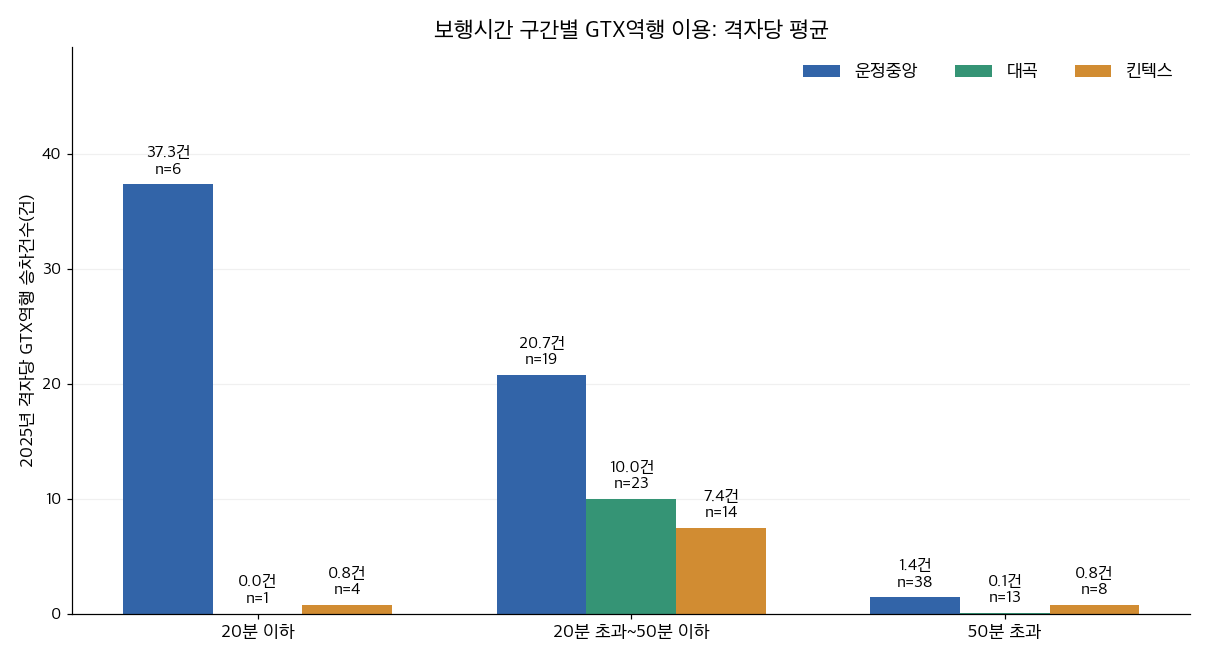

In [6]:
band_feeder_012=band_012['역행격자당평균'].unstack('권역').reindex(index=BANDS_012,columns=ORDER_012)
print('격자당 GTX역행 이용건수(건, 0건 격자 포함)');display(band_feeder_012.round(2))
fig,ax=plt.subplots(figsize=(11,6));x=np.arange(3);width=.24
for j,station in enumerate(ORDER_012):
    values=band_feeder_012[station];bars=ax.bar(x+(j-1)*width,values,width,label=station,color=COLORS_012[station])
    ax.bar_label(bars,labels=[f'{v:.1f}건\nn={int(nn)}' for v,nn in zip(values,band_n_012[station])],
                 padding=5,fontsize=11)
ax.set_xticks(x,BANDS_012);ax.set_ylim(0,band_feeder_012.to_numpy().max()*1.32)
ax.set_title('보행시간 구간별 GTX역행 이용: 격자당 평균');ax.set_ylabel('2025년 격자당 GTX역행 승차건수(건)')
ax.legend(ncol=3,frameon=False);clean_axes_012(ax);fig.tight_layout();plt.show()

### 이용된 연계노선 구조

H13f는 도착역 기준이므로 아래 표는 2025년 원본 기록에서 **승차 격자 권역별로 재집계**한다. 해당 지역의 전체 운행 노선 수나 배차 공급량을 뜻하지 않는다. 1위 노선 비중은 각 권역의 GTX역행 이용건수 합계 대비 비율이다.

,이용 관측 노선 수,1위 노선,1위 노선 이용건수,1위 노선 비중(%)
권역,,,,
운정중앙,9,089,256,38.10
대곡,6,95,183,79.57
킨텍스,12,83,54,47.79


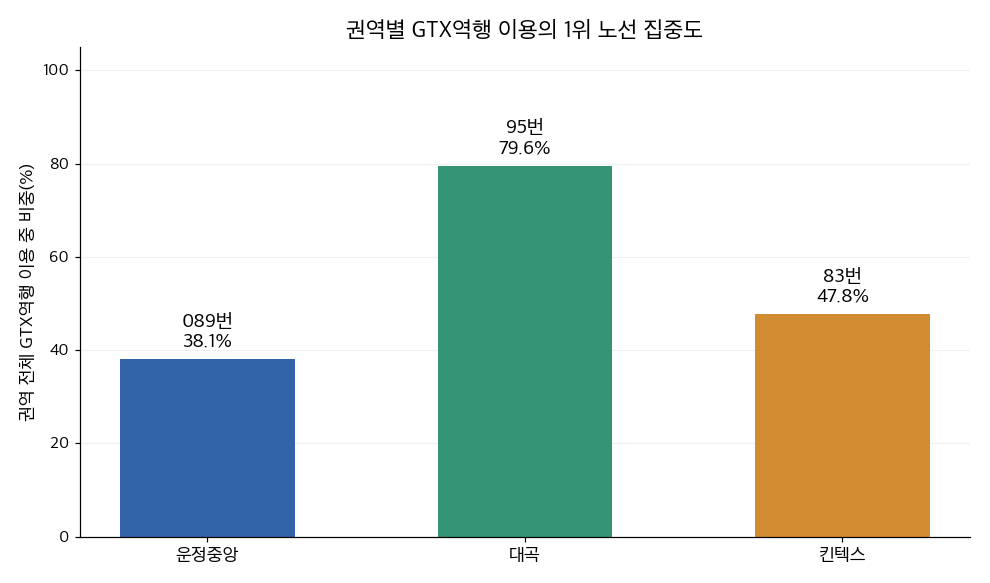

In [7]:
# H13f의 열은 도착역 기준이다. 이용량 표와 동일한 승차 권역 기준으로 원본에서 재집계.
import re
stops_dir_012 = ROOT_012 / 'data/processed/gtx_a/feeder_bus/stops'
stop_old_012 = pd.read_csv(stops_dir_012 / 'BusStop_20251106_파주고양서울일부.csv',dtype=str)
stop_new_012 = pd.read_csv(stops_dir_012 / '2025_신설정류장_좌표_GBIS.csv',dtype=str)
def normalize_stop_012(series):
    return series.astype(str).str.replace('.0','',regex=False).str.lstrip('0')
stop_names_012 = pd.concat([
    pd.Series(stop_new_012['정류장명'].values,index=normalize_stop_012(stop_new_012['정류장 ID'])),
    pd.Series(stop_old_012.sttn_nm.values,index=normalize_stop_012(stop_old_012.sttn_id))])
stop_names_012 = stop_names_012[~stop_names_012.index.duplicated()]
station_ids_012 = set(stop_names_012[stop_names_012.str.contains('운정중앙역|킨텍스역|대곡역',na=False)].index)
map_cells_012 = pd.read_csv(next((ROOT_012/'data/processed/gtx_a').glob('16_*.csv')),dtype=str)
stop_cells_012 = {sid.lstrip('0'):int(cid) for cid,value in zip(map_cells_012['셀 ID'],map_cells_012['2025년 정류장 ID'])
                  for sid in re.findall(r'\d{6,}',value)}
raw_files_012 = [p for p in (ROOT_012/'data/raw/gtx_a/feeder_bus/transport_card').glob('경기_20251106_*.csv') if p.stat().st_size>10]
assert raw_files_012, '승차권역별 노선 비교에는 로컬 마을버스 원자료가 필요합니다.'
raw_routes_012 = pd.concat([pd.read_csv(p,dtype=str,usecols=['opr_ymd','rte_id','ride_sttn_id','goff_sttn_id']) for p in raw_files_012],ignore_index=True)
assert raw_routes_012.opr_ymd.eq('20251106').all()
raw_routes_012['on'] = normalize_stop_012(raw_routes_012.ride_sttn_id)
raw_routes_012['off'] = normalize_stop_012(raw_routes_012.goff_sttn_id)
raw_routes_012['셀 ID'] = raw_routes_012['on'].map(stop_cells_012)
raw_routes_012 = raw_routes_012[raw_routes_012['셀 ID'].notna() & raw_routes_012['off'].isin(station_ids_012) & ~raw_routes_012['on'].isin(station_ids_012)].copy()
raw_routes_012['셀 ID'] = raw_routes_012['셀 ID'].astype(int)
reference_012 = feeder_012.set_index('셀 ID')['GTX역행 2025']
np.testing.assert_array_equal(raw_routes_012.groupby('셀 ID').size().reindex(reference_012.index,fill_value=0),reference_012)
raw_routes_012['권역'] = raw_routes_012['셀 ID'].map(base_012.set_index('셀 ID')['nearest_station'])
origin_routes_012 = raw_routes_012.groupby(['rte_id','권역']).size().unstack('권역',fill_value=0).reindex(columns=ORDER_012,fill_value=0)
route_labels_012 = routes_012.set_index('rte_id')['노선번호']
origin_routes_012['노선번호'] = origin_routes_012.index.to_series().map(route_labels_012).fillna(origin_routes_012.index.to_series())
route_rows_012=[]
for station in ORDER_012:
    observed=origin_routes_012.loc[origin_routes_012[station]>0].sort_values(station,ascending=False,kind='stable')
    total=observed[station].sum();assert total==region_012.loc[station,'GTX역행2025']
    top=observed.iloc[0]
    route_rows_012.append({'권역':station,'이용 관측 노선 수':len(observed),'1위 노선':top['노선번호'],
                           '1위 노선 이용건수':int(top[station]),'1위 노선 비중(%)':100*top[station]/total})
route_summary_012=pd.DataFrame(route_rows_012).set_index('권역').reindex(ORDER_012)
display(route_summary_012.round(2))
fig,ax=plt.subplots(figsize=(9,5.3))
bars=ax.bar(ORDER_012,route_summary_012['1위 노선 비중(%)'],color=[COLORS_012[s] for s in ORDER_012],width=.55)
ax.bar_label(bars,labels=[f"{row['1위 노선']}번\n{row['1위 노선 비중(%)']:.1f}%" for _,row in route_summary_012.iterrows()],
             padding=6,fontsize=13,fontweight='bold')
ax.set_ylim(0,105);ax.set_title('권역별 GTX역행 이용의 1위 노선 집중도');ax.set_ylabel('권역 전체 GTX역행 이용 중 비중(%)')
clean_axes_012(ax);fig.tight_layout();plt.show()

### 광역버스 변화와 GTX역행 이용을 함께 보기

위아래 그래프는 같은 권역 순서이며 **서로 다른 지표·축**을 사용한다. 위는 광역버스 변화량, 아래는 2025년 역행 이용 수준이다. 두 막대의 크기를 빼거나 전환율로 해석하면 안 된다.

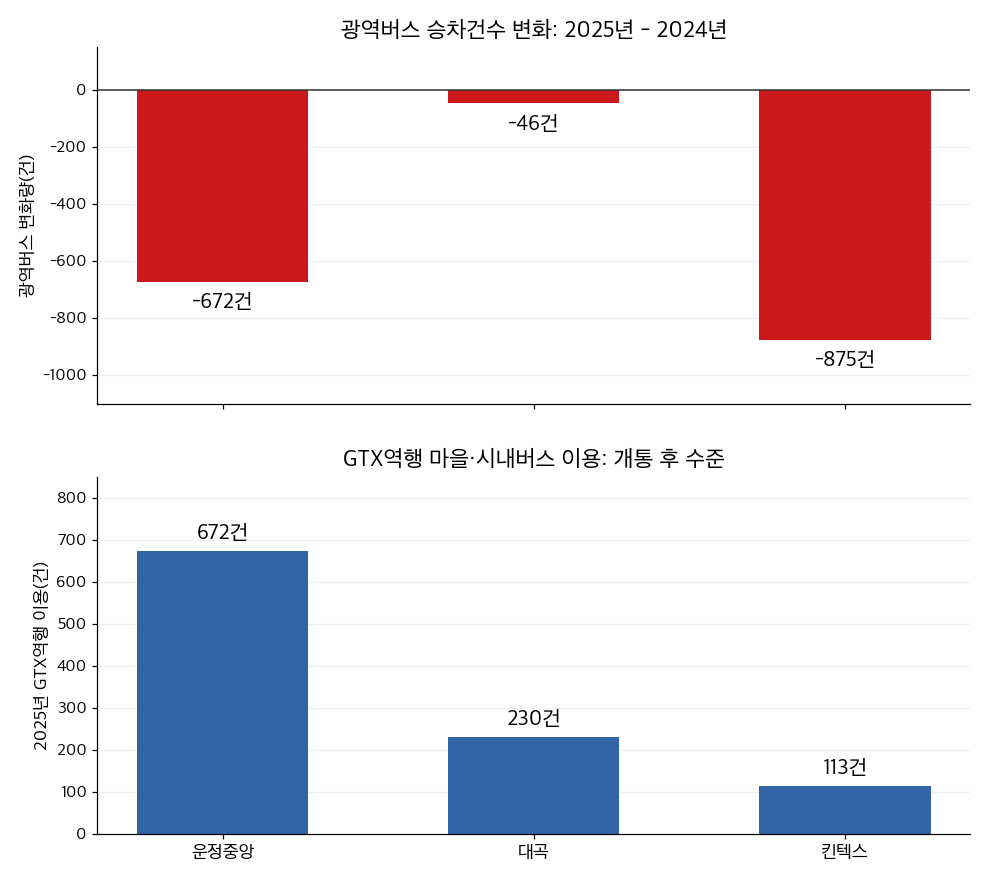

In [8]:
fig,axes=plt.subplots(2,1,figsize=(9,8),sharex=True)
ax=axes[0];values=region_012['변화량'];bars=ax.bar(ORDER_012,values,color='#CB181D',width=.55)
ax.axhline(0,color='#333333',lw=1);ax.set_ylim(-1100,150)
for bar,value in zip(bars,values):
    ax.annotate(f'{int(value):+,}건',(bar.get_x()+bar.get_width()/2,value),xytext=(0,-7),
                textcoords='offset points',ha='center',va='top',fontsize=14,fontweight='bold')
ax.set_ylabel('광역버스 변화량(건)');ax.set_title('광역버스 승차건수 변화: 2025년 - 2024년');clean_axes_012(ax)
ax=axes[1];values=region_012['GTX역행2025'];bars=ax.bar(ORDER_012,values,color='#3264A8',width=.55)
ax.bar_label(bars,labels=[f'{int(v):,}건' for v in values],padding=6,fontsize=14,fontweight='bold')
ax.set_ylim(0,850);ax.set_ylabel('2025년 GTX역행 이용(건)');ax.set_title('GTX역행 마을·시내버스 이용: 개통 후 수준')
clean_axes_012(ax);fig.tight_layout(h_pad=2.2);plt.show()

## 4. 회귀 결과와 연결

기존 H12 결과를 읽으며 **재추정하지 않는다.** 운정 더미 +8.2건은 포함 변수들을 통제한 운정 권역과 다른 두 권역의 평균 차이다. 환승센터 단독 효과로 해석하지 않는다.

In [9]:
main_coef_012=coef_012.loc[coef_012['모형']=='주모형 (126)', ['변수','계수','HC3 표준오차','p값']].copy()
main_fit_012=fit_012.loc[fit_012['모형']=='주모형 (126)'].copy()
assert len(main_coef_012)==6 and int(main_fit_012['n'].iloc[0])==126
print('종속변수: 2025년 GTX역행 마을·시내버스 승차건수 / OLS HC3')
display(main_coef_012);display(main_fit_012)

종속변수: 2025년 GTX역행 마을·시내버스 승차건수 / OLS HC3


,변수,계수,HC3 표준오차,p값
0,log(1+GTX역 보행시간),-8.8028,3.1073,0.0046
1,20~50대 인구 2025(명),-0.0021,0.0055,0.7029
2,log(1+건축물 연면적),7.5633,3.3883,0.0256
3,주거지역 비율(%),0.0267,0.0733,0.7158
4,1km 안 기존 철도역 수,-4.5829,2.6594,0.0848
5,운정 더미,8.2323,3.8902,0.0343


,모형,종속,n,R²,수정 R²,F,모형 p값
0,주모형 (126),GTX역행 2025,126,0.2763,0.2398,4.9106,0.0002


## 정리와 해석 범위

- 운정중앙: 광역버스 합계 감소와 2025년 GTX역행 연계버스 이용이 크게 나타났다. 시설·노선 여건은 현장자료와 함께 비교한다.
- 대곡: 광역버스 합계가 비교적 유지됐고, 관측된 GTX역행 이용은 95번 노선에 집중됐다. 연계버스 이용 합계는 킨텍스보다 많으므로 “두 교통수단 모두 변화/이용이 약하다”로 단순화하지 않는다.
- 킨텍스: 광역버스 감소가 컸지만, 분석격자 내부 GTX역행 마을·시내버스 이용은 상대적으로 적었다.
- 넓은 보행시간 구간 비교는 조건을 완전히 통제한 분석이 아니다. 기존 수요 규모·노선 공급·지역 특성이 다를 수 있다.
- 역행 이용은 실제 GTX 환승을 확인한 값이 아니며, 합성자료·단일 비교일·역명 정류장 판정의 한계를 갖는다.
- 이 비교만으로 시설·환승센터가 광역버스 감소를 유발했다거나 같은 사람이 GTX로 전환했다고 주장하지 않는다.

**집계 기준 주의:** 기존 H13f는 하차 GTX역별(운정중앙 673·대곡 247·킨텍스 95건)이며, 승차 권역 합계(672·230·113건)와 다르다. 위 노선 비교는 원본에서 승차 권역 기준으로 재집계하여 모든 격자의 H11a 값과 일치함을 검증했다. 기존 H13f 파일은 수정하지 않았다.

**다음 보완:** 답사 사진과 메모로 시설표 빈칸을 확인하고, 버스 주행시간·대기시간·하차 후 개찰구 이동을 구분하여 측정한다.